<a href="https://colab.research.google.com/github/strangestmahi/statistical-foundation-of-data-science/blob/main/FinalPractical/FinalPractical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(16)
demand = np.maximum(np.round(rng.normal(80, 20, 20000)), 0).astype(int)

cost, price, salvage = 150, 400, 50

print("Days simulated :", len(demand))
print("Mean demand    :", round(demand.mean(), 2))
print("Std of demand  :", round(demand.std(), 2))
print("Min / Max      :", demand.min(), "/", demand.max())

Days simulated : 20000
Mean demand    : 79.99
Std of demand  : 19.81
Min / Max      : 9 / 170


In [2]:
def expected_profit(Q, salvage_value):
    sold = np.minimum(demand, Q)
    leftover = np.maximum(Q - demand, 0)
    profit = price * sold + salvage_value * leftover - cost * Q
    return profit.mean()

Q_values = np.arange(50, 131)
profits = np.array([expected_profit(Q, salvage) for Q in Q_values])

table = pd.DataFrame({"Q": Q_values, "Expected profit (Rs)": profits.round(2)})
print(table.iloc[::10].to_string(index=False))

best_Q = Q_values[profits.argmax()]
best_profit = profits.max()
print("\nBest Q (simulation)      :", best_Q)
print("Expected profit at best Q: Rs", round(best_profit, 2))
print("Expected profit at Q = 80: Rs", round(profits[Q_values == 80][0], 2))

  Q  Expected profit (Rs)
 50              12309.88
 60              14437.81
 70              16134.56
 80              17218.72
 90              17632.95
100              17428.96
110              16799.08
120              15940.20
130              14984.93

Best Q (simulation)      : 91
Expected profit at best Q: Rs 17637.85
Expected profit at Q = 80: Rs 17218.72


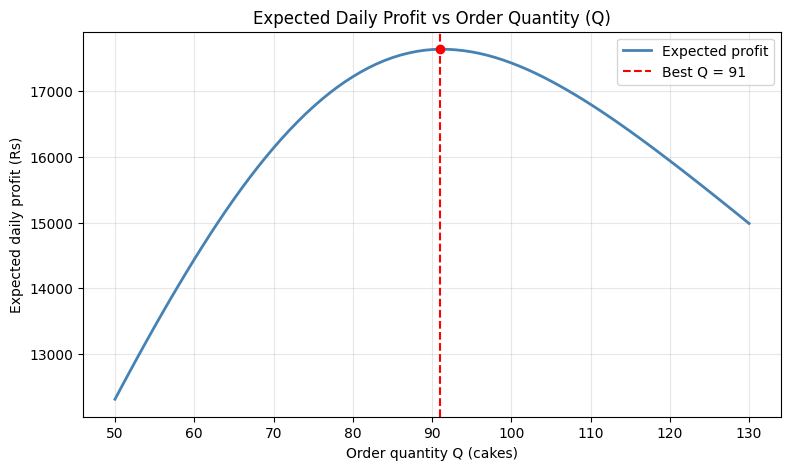

In [3]:
plt.figure(figsize=(9, 5))
plt.plot(Q_values, profits, color="steelblue", lw=2, label="Expected profit")
plt.axvline(best_Q, color="red", linestyle="--", label=f"Best Q = {best_Q}")
plt.scatter([best_Q], [best_profit], color="red", zorder=5)
plt.title("Expected Daily Profit vs Order Quantity (Q)")
plt.xlabel("Order quantity Q (cakes)")
plt.ylabel("Expected daily profit (Rs)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [4]:
cr = (price - cost) / (price - salvage)
z = stats.norm.ppf(cr)
q_theory = 80 + 20 * z

print("Critical ratio (p-c)/(p-s):", round(cr, 4))
print("Normal quantile z         :", round(z, 4))
print("Theoretical Q*            :", round(q_theory, 2))
print("Simulated best Q          :", best_Q)

Critical ratio (p-c)/(p-s): 0.7143
Normal quantile z         : 0.5659
Theoretical Q*            : 91.32
Simulated best Q          : 91


In [5]:
p_stockout = np.mean(demand > best_Q)
avg_leftover = np.maximum(best_Q - demand, 0).mean()

print("Best Q                          :", best_Q)
print("Probability of running out      :", round(p_stockout, 4))
print("Average leftover cakes          :", round(avg_leftover, 2))

Best Q                          : 91
Probability of running out      : 0.2812
Average leftover cakes          : 14.61


In [6]:
profits0 = np.array([expected_profit(Q, 0) for Q in Q_values])
best_Q0 = Q_values[profits0.argmax()]

cr0 = (price - cost) / (price - 0)
z0 = stats.norm.ppf(cr0)

print("Critical ratio (salvage 0)  :", round(cr0, 4))
print("Theoretical Q*              :", round(80 + 20 * z0, 2))
print("Best Q (simulation)         :", best_Q0)
print("Expected profit at best Q   : Rs", round(profits0.max(), 2))
print("P(running out)              :", round(np.mean(demand > best_Q0), 4))
print("Average leftover cakes      :", round(np.maximum(best_Q0 - demand, 0).mean(), 2))

Critical ratio (salvage 0)  : 0.625
Theoretical Q*              : 86.37
Best Q (simulation)         : 86
Expected profit at best Q   : Rs 16982.72
P(running out)              : 0.3746
Average leftover cakes      : 11.29


## Follow-up 1

The critical ratio is (p - c) / (p - s) = 250 / 350 = 0.7143. This is more than 0.5, so the best Q is above the middle of the demand, which is 80. Running out of a cake loses a profit of Rs 250 (400 - 150), but having one cake left over loses only Rs 100 (150 - 50). Missing a sale costs more than a leftover cake, so it is better to bake a few extra. Using z = 0.5659, Q* = 80 + 20 x 0.5659 = 91.32, and the simulation gave Q = 91.

## Follow-up 2

Now a leftover cake loses the full Rs 150, so the critical ratio becomes 250 / 400 = 0.625. This gives z = 0.3186 and Q* = 86.37. The simulation gives a best Q of 86, which is 5 cakes less than before (91). The expected profit also falls from Rs 17,637.85 to Rs 16,982.72, a drop of about Rs 655. The bakery should order fewer cakes because leftovers now cost more. The chance of running out goes up (0.2812 to 0.3746) and the average leftover goes down (14.61 to 11.29).